# Assessment Notebook


### Numerical arrays.

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

## Problem 1: Exploring Petal Length

Problem 1 involves investigating the distribution of petal length across the Iris dataset. We began by plotting a histogram with a superimposed normal distribution for all 150 flowers using the overall mean and standard deviation. Next, we generated separate histograms and fitted normal curves for each of the three species (setosa, versicolor, and virginica) based on their individual statistical metrics. Finally, our comparison revealed that while a normal distribution is an unsuitable model for the combined dataset due to its multi-peaked (bimodal) nature, it serves as a reasonable and accurate model when applied to each species individually.

In [13]:
# Load the Iris dataset
df = sns.load_dataset('iris')

In [14]:
# Define a function for the normal distribution curve
def normal_curve(x, mean, std):
    return (1 / (std * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mean) / std) ** 2)

### 1 & 2. Histogram for all 150 flowers + Normal distribution 

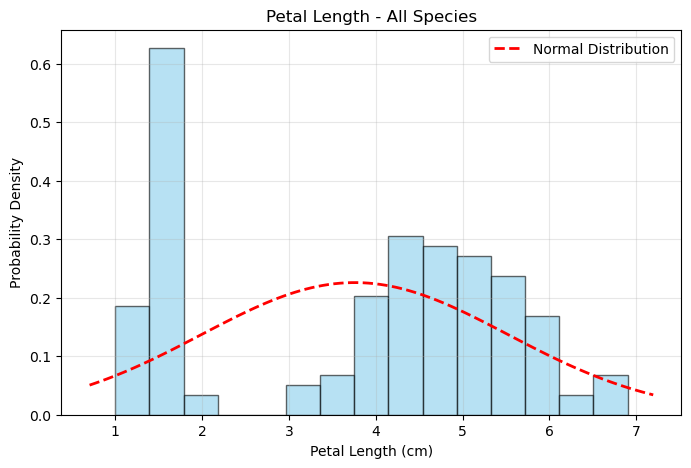

In [ ]:

overall_mean = df['petal_length'].mean()
overall_std = df['petal_length'].std()

plt.figure(figsize=(8, 5))
count, bins, ignored = plt.hist(
    df['petal_length'], bins=15, density=True, alpha=0.6, color='skyblue', edgecolor='black'
)

xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
y = normal_curve(x, overall_mean, overall_std)
plt.plot(x, y, 'r--', linewidth=2, label='Normal Distribution')

plt.title('Petal Length - All Species')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Probability Density')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 3. Separate histograms for each of the 3 species 

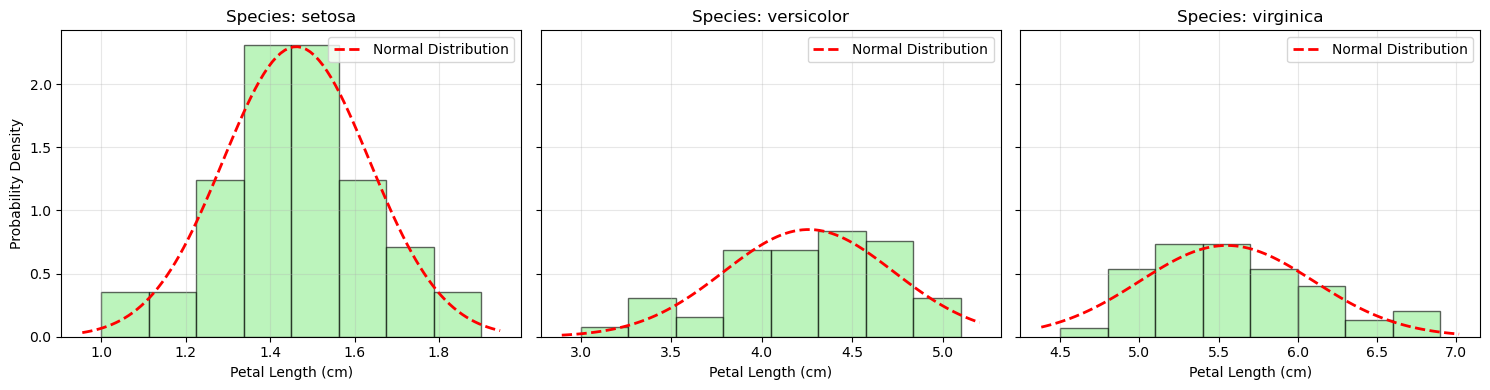

In [ ]:
species_list = df['species'].unique()
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for i, species in enumerate(species_list):
  # Select data for a single species only
  subset = df[df['species'] == species]['petal_length']
  mu = subset.mean()
  std = subset.std()

  # Draw the histogram for the species
  axes[i].hist(
      subset, bins=8, density=True, alpha=0.6, color='lightgreen', edgecolor='black'
  )

  # Draw the normal curve for this species
  xmin, xmax = axes[i].get_xlim()
  x = np.linspace(xmin, xmax, 100)
  y = normal_curve(x, mu, std)
  axes[i].plot(x, y, 'r--', linewidth=2, label='Normal Distribution')

  axes[i].set_title(f'Species: {species}')
  axes[i].set_xlabel('Petal Length (cm)')
  if i == 0:
    axes[i].set_ylabel('Probability Density')
  axes[i].legend()
  axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 4. Report the mean and standard deviation 

In [ ]:
print("--- STATISTICAL RESULTS (Point 4) ---")
print(f"Complete dataset -> Mean: {overall_mean:.2f}, Standard Deviation: {overall_std:.2f}\n")

print("For individual species:")
species_stats = df.groupby('species')['petal_length'].agg(['mean', 'std']).reset_index()
print(species_stats.to_string(index=False))

--- STATISTICAL RESULTS (Point 4) ---
Complete dataset -> Mean: 3.76, Standard Deviation: 1.77

For individual species:
   species  mean      std
    setosa 1.462 0.173664
versicolor 4.260 0.469911
 virginica 5.552 0.551895


### 5. Description and Comparison of Distributions

#### Overall Distribution (All 150 Flowers)

Shape: The histogram for the complete dataset is bimodal (or multi-modal) rather than bell-shaped. It clearly shows multiple separate clusters instead of a single central peak.

Normal Model Suitability: A normal distribution is not a reasonable model for the combined dataset. Because the data merges three entirely different species with distinct physical sizes, the superimposed normal curve fails to fit the actual multi-peaked data shape.

#### Species-Specific Distributions

Iris setosa: Features a very narrow and tightly clustered distribution with a mean around $1.46\text{ cm}$ and a tiny standard deviation ($0.17\text{ cm}$).While the data is heavily concentrated, a normal distribution serves as an acceptable approximation, though its variance is uniquely low compared to the other species.

Iris versicolor: Displays a symmetric, bell-shaped distribution centered around a mean of $4.26\text{ cm}$.A normal distribution appears to be a very reasonable and accurate model for this species, matching the natural biological variation well.

Iris virginica: Shows a symmetric bell-shaped distribution around a mean of $5.55\text{ cm}$ with a slightly wider spread ($\sigma = 0.55\text{ cm}$).A normal distribution is also a reasonable and effective model for this species.

#### Conclusion

While treating the Iris dataset as a single population makes the normal distribution a poor choice, evaluating the species individually reveals that normal distributions serve as good and reasonable models for each specific subgroup.

## Problem 2: Correlation Between Petal Length and Petal Width


## Problem 3: Comparing Species Using t-Tests

## Problem 4: Comparing the Species Using ANOVA

## End